# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import GVLMDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/gvlm/",
}
dataset = GVLMDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 17


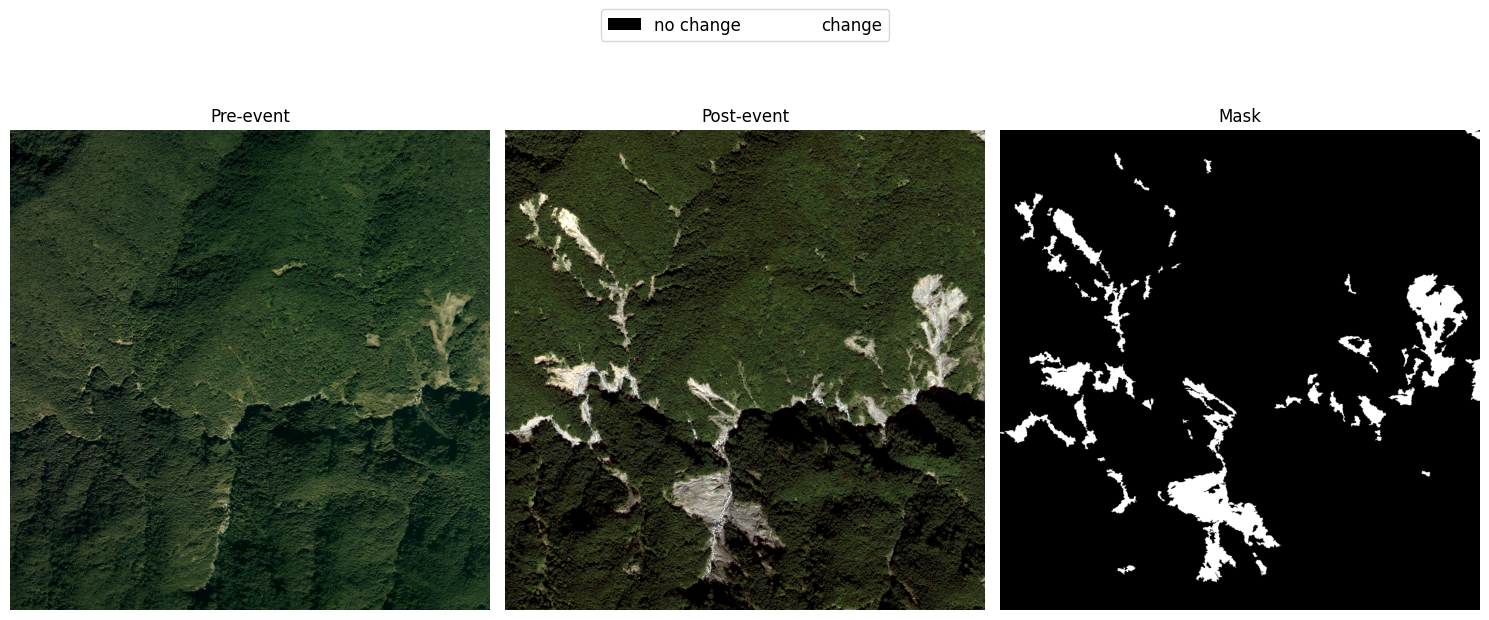

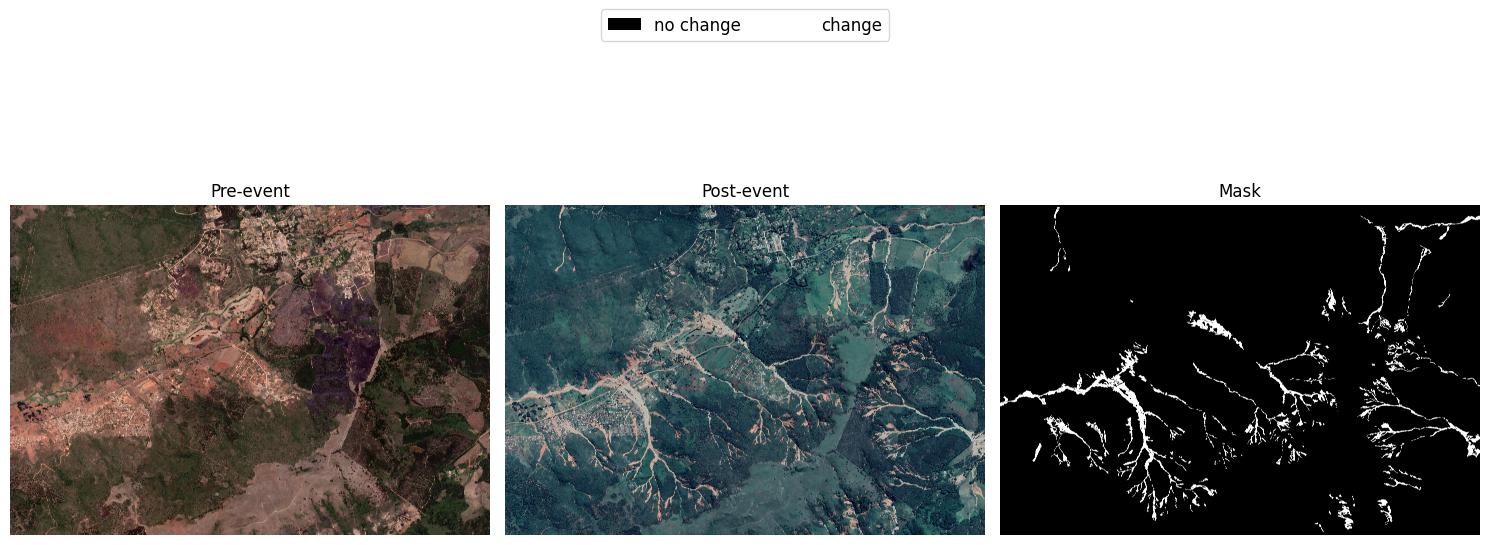

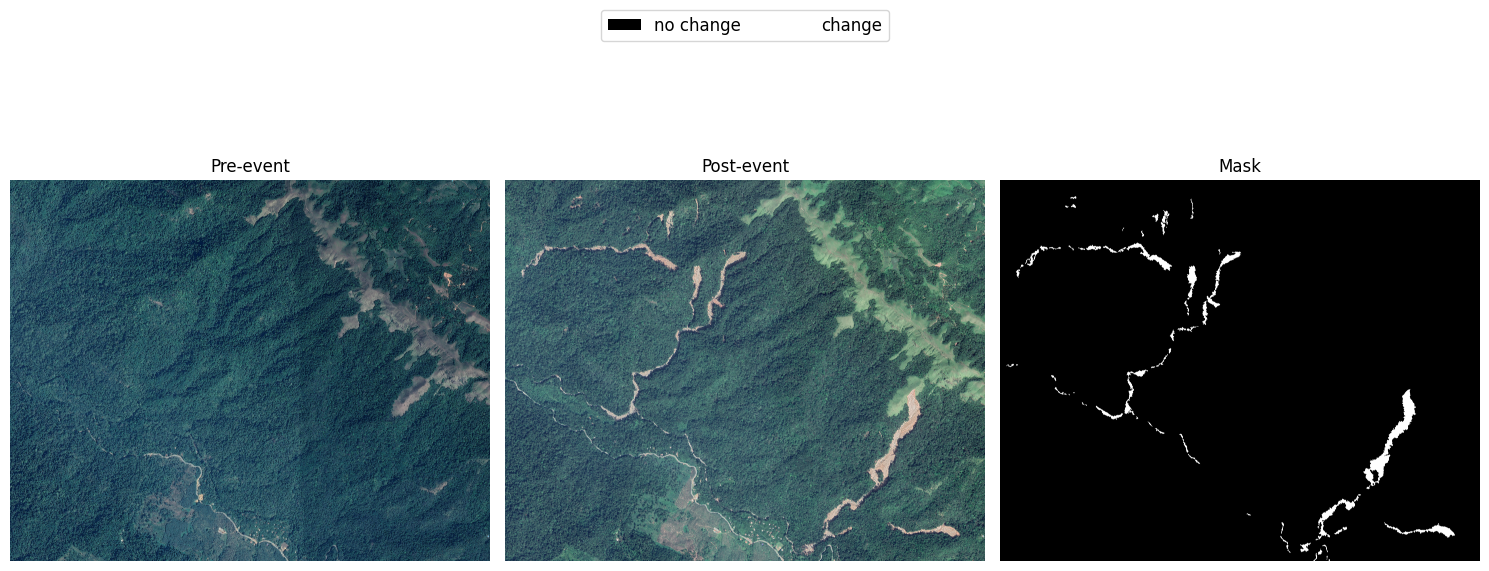

In [6]:
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(15);

In [35]:
dataset.data_distribution_table()

,Number of pixels
no change,457260555.0
change,32411533.0


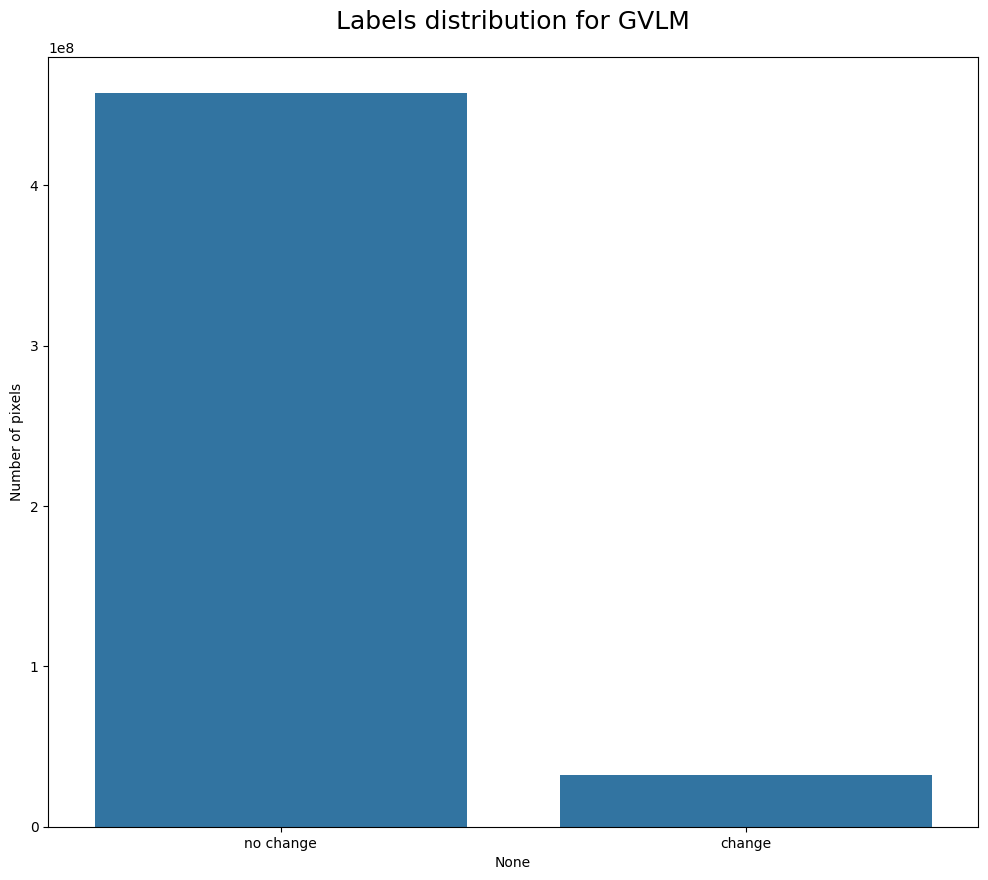

In [36]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/gvlm/",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = GVLMDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/gvlm/",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = GVLMDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(10, 4)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/gvlm"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-28 12:59:56,440 INFO Starting training.
training: 100%|██████████| 3/3 [03:06<00:00, 62.07s/it] 
2026-01-28 13:03:02,701 INFO epoch: 1, loss:  0.29617
testing on train set: 100%|██████████| 3/3 [04:24<00:00, 88.14s/it] 
2026-01-28 13:07:28,317 INFO Accuracy:0.5343238830566406, Accuracy per Class:[0.10687561 0.96177216], Precision Micro:0.0047556142668428005, Precision Macro:0.0023778071334214002, Precision Weighted:0.00013847826732068836, Precision per Class:[0.         0.00475561], Recall Micro:5.971406913230481e-05, Recall Macro:0.0010253489034463116, Recall Weighted:5.971406913230481e-05, Recall per Class:[0.        0.0020507], F1_score Micro:0.00011794713019886386, F1_score Macro:0.001432835820895312, F1_score Weighted:8.344521262626523e-05, F1_score per Class:[0.         0.00286567], IOU:5.897704318593987e-05, IOU mean:0.0007174458926222648, IOU per Class:[0.         0.00143489]
training: 100%|██████████| 3/3 [03:21<00:00, 67.07s/it] 
2026-01-28 13:10:49,522 INFO epoch: 2,

## Predictions

2026-01-29 07:40:20,754 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/gvlm/checkpoint.pth.tar
2026-01-29 07:40:21,210 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/gvlm/checkpoint.pth.tar at epoch 51


3


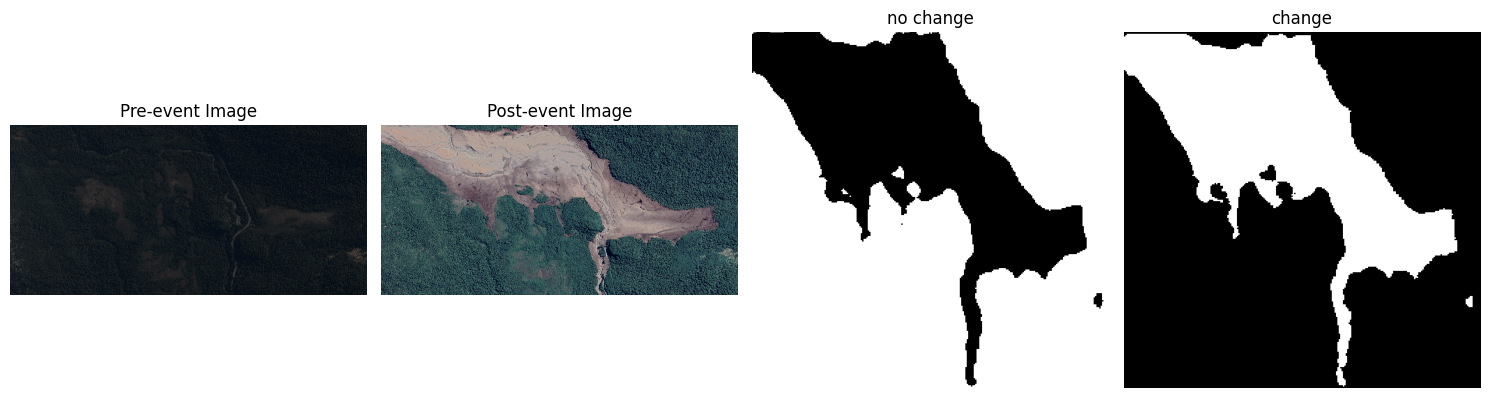

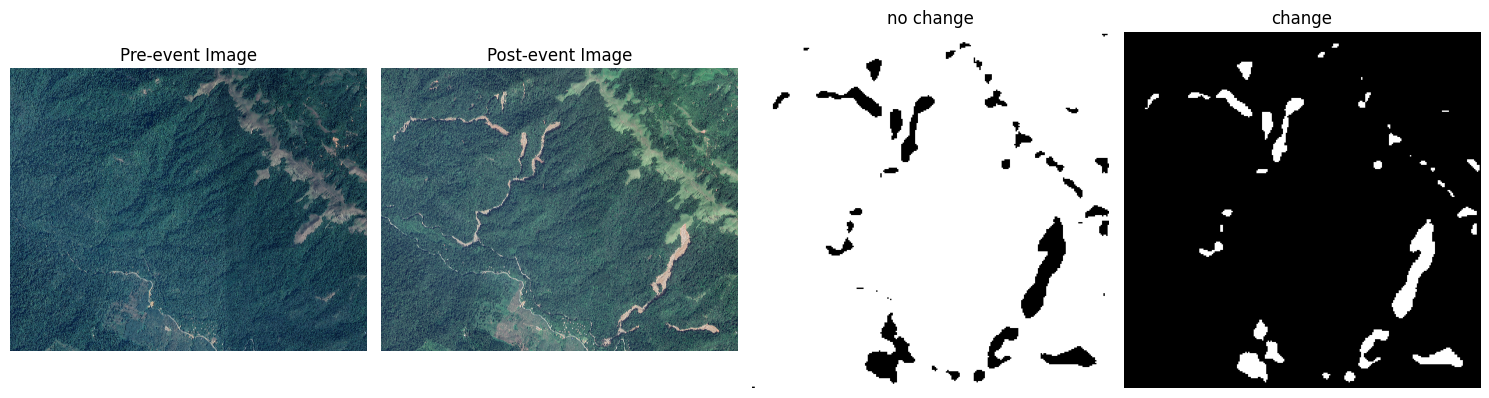

In [ ]:
model_path = "./data/experiments/gvlm/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/gvlm/",
    "mode": "test",
}
test_dataset = GVLMDataset(test_dataset_config)
print(len(test_dataset))

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)

image1 = test_dataset[1][0][0]
image2 = test_dataset[1][0][1]
fig = model.predict_masks(image1, image2, labels, transform)